<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U6_trees_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 6: Decision Trees and Ensembles

- **Registration number:** COM/00443/23
- **owner:** Emmanuel Rotich (Member 5)
- **Module:** 7

**Contents**
1. Setup and stratified split
2. Decision tree (depth 3) and depth curve
3. Entropy and information gain by hand
4. Random forest and gradient boosting
5. Feature importance
6. Written answer

In [1]:
# Mount Drive, import libraries and load the cleaned data from Task 2.2
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

base = "/content/drive/MyDrive/CSC4110_G01/"
out = base + "outputs/"
df_clean = pd.read_csv(base + "data/clean_students.csv")

# Features exclude Exam_Score (it defines the target); same stratified split as Task 4
X = df_clean.drop(columns=['Exam_Score', 'high_score'])
y = df_clean['high_score']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

Mounted at /content/drive
(5285, 22) (1322, 22)


tree3 train accuracy: 0.8615 | test accuracy: 0.8601


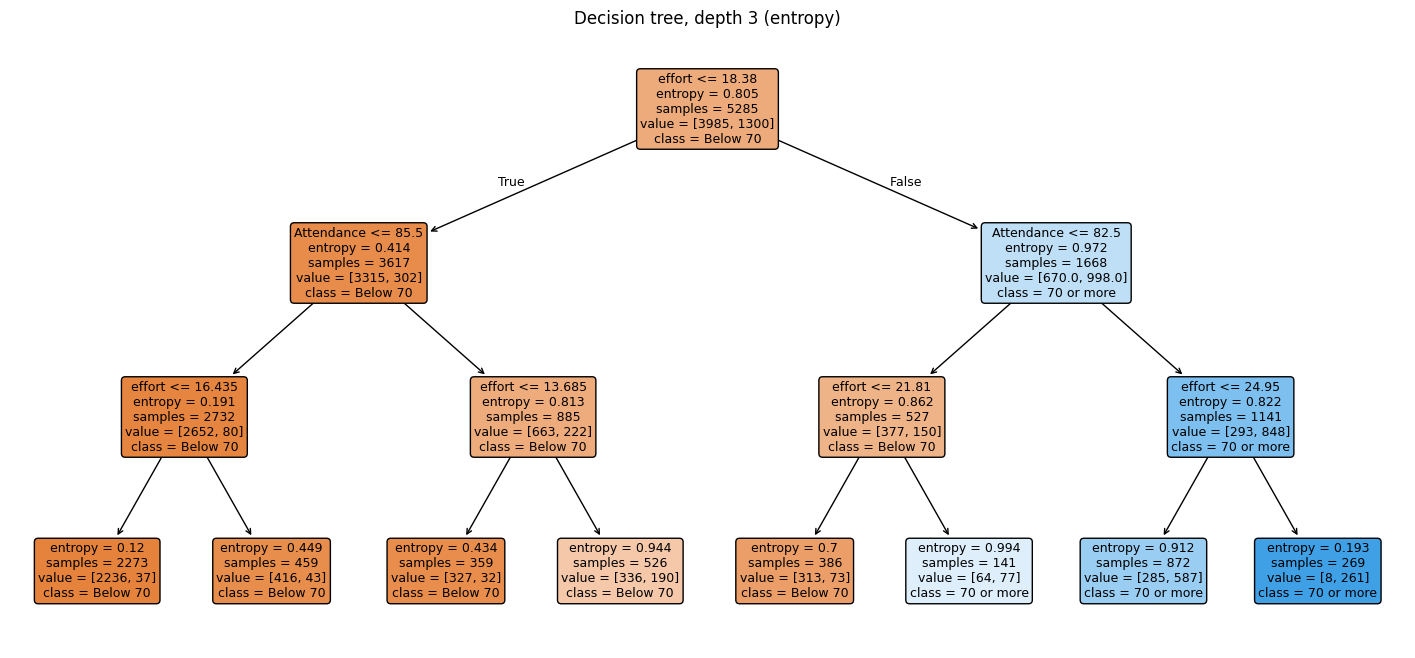

Root split: effort <= 18.3800


In [2]:
# Part (a) step 1: a shallow tree (depth 3) using entropy. Trees need no scaling.
tree3 = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
tree3.fit(X_train, y_train)
print("tree3 train accuracy:", round(tree3.score(X_train, y_train), 4),
      "| test accuracy:", round(tree3.score(X_test, y_test), 4))

# Part (a) step 2: draw the tree and save it
plt.figure(figsize=(18, 8))
plot_tree(tree3, feature_names=list(X.columns), class_names=['Below 70', '70 or more'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision tree, depth 3 (entropy)')
plt.savefig(out + 'tree_depth3.png', dpi=150, bbox_inches='tight')
plt.show()

# The root split in words
root_feature = X.columns[tree3.tree_.feature[0]]
root_threshold = tree3.tree_.threshold[0]
print(f"Root split: {root_feature} <= {root_threshold:.4f}")

    train_acc  test_acc
1      0.8161    0.8116
2      0.8590    0.8457
3      0.8615    0.8601
4      0.8693    0.8548
5      0.8844    0.8790
6      0.8956    0.8616
7      0.9156    0.8707
8      0.9302    0.8669
9      0.9478    0.8691
10     0.9678    0.8707
11     0.9794    0.8691
12     0.9875    0.8707
13     0.9939    0.8737
14     0.9970    0.8744
15     0.9991    0.8722


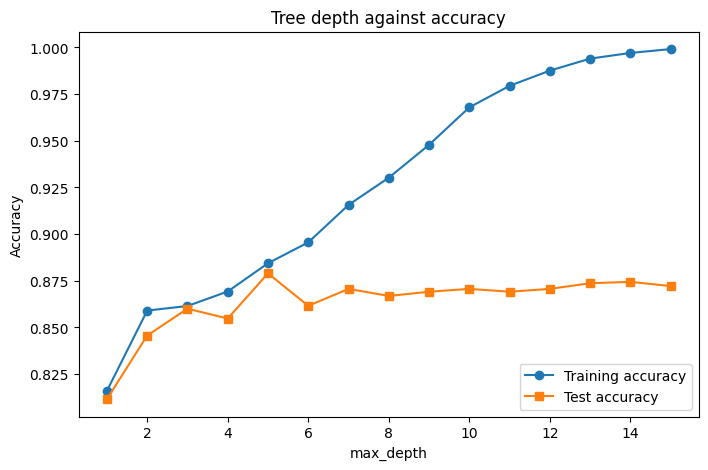

Depth with the highest test accuracy: 5 -> 0.879


In [3]:
# Part (a) step 3: trees of depth 1 to 15, training and test accuracy of each
depth_results = {}
for d in range(1, 16):
    t = DecisionTreeClassifier(max_depth=d, criterion='entropy', random_state=42).fit(X_train, y_train)
    depth_results[d] = {'train_acc': t.score(X_train, y_train), 'test_acc': t.score(X_test, y_test)}
depth_df = pd.DataFrame(depth_results).T
print(depth_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(depth_df.index, depth_df['train_acc'], 'o-', label='Training accuracy')
plt.plot(depth_df.index, depth_df['test_acc'], 's-', label='Test accuracy')
plt.title('Tree depth against accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.savefig(out + 'depth_curve.png', dpi=150, bbox_inches='tight')
plt.show()
best_depth = int(depth_df['test_acc'].idxmax())
print("Depth with the highest test accuracy:", best_depth, "->", round(depth_df['test_acc'].max(), 4))

In [4]:
# Part (b): entropy and information gain written from scratch
def entropy(labels):
    # entropy = -sum(p * log2(p)) over the classes present
    p = np.bincount(np.asarray(labels).astype(int)) / len(labels)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def information_gain(y_parent, y_left, y_right):
    # gain = parent entropy minus the size-weighted entropy of the two children
    n = len(y_parent)
    return entropy(y_parent) - (len(y_left) / n) * entropy(y_left) - (len(y_right) / n) * entropy(y_right)

# Gain of tree3's first split, computed on the training rows
mask = X_train[root_feature] <= root_threshold
ig_root = information_gain(y_train, y_train[mask], y_train[~mask])
print(f"Parent entropy: {entropy(y_train):.4f}")
print(f"Information gain of the root split ({root_feature}): {ig_root:.4f}")

# Compare with a split on Sleep_Hours at its median
median_sleep = X_train['Sleep_Hours'].median()
m2 = X_train['Sleep_Hours'] <= median_sleep
ig_sleep = information_gain(y_train, y_train[m2], y_train[~m2])
print(f"Information gain of Sleep_Hours <= {median_sleep}: {ig_sleep:.4f}")
print("Root split beats the Sleep_Hours split:", ig_root > ig_sleep)

Parent entropy: 0.8048
Information gain of the root split (effort): 0.2145
Information gain of Sleep_Hours <= 7.0: 0.0000
Root split beats the Sleep_Hours split: True


In [5]:
# Part (c): bagging (random forest) and boosting (gradient boosting)
forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)
boost = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

# Test accuracy and F1 (class 1) of the single tree, the forest and boosting
models6 = {'Decision tree (depth 3)': tree3, 'Random forest': forest, 'Gradient boosting': boost}
results_trees = pd.DataFrame({
    name: {'Accuracy': accuracy_score(y_test, m.predict(X_test)),
           'F1': f1_score(y_test, m.predict(X_test))}
    for name, m in models6.items()}).T
print(results_trees.round(4))

                         Accuracy      F1
Decision tree (depth 3)    0.8601  0.7021
Random forest              0.9213  0.8249
Gradient boosting          0.9349  0.8595


effort                      0.3028
Attendance                  0.2083
Hours_Studied               0.1036
Previous_Scores             0.0716
Tutoring_Sessions           0.0381
Access_to_Resources         0.0346
Parental_Involvement        0.0296
Sleep_Hours                 0.0246
Physical_Activity           0.0225
Parental_Education_Level    0.0207
dtype: float64


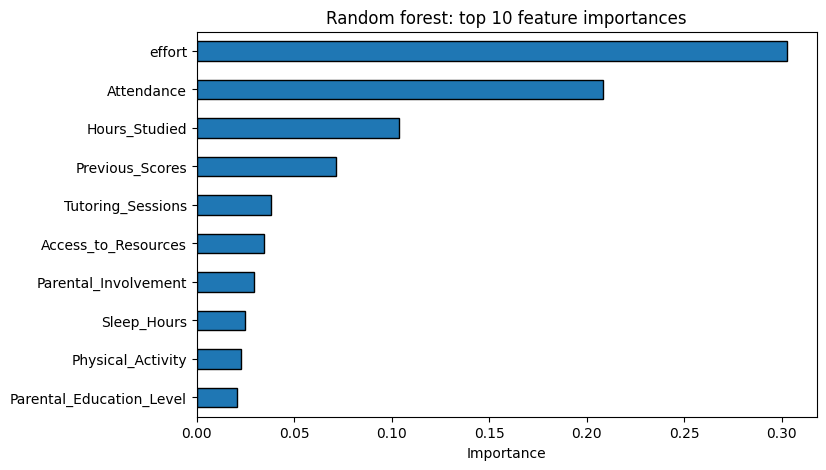

In [6]:
# Part (d) step 1: random forest feature importances, top 10 plotted
importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10).round(4))
plt.figure(figsize=(8, 5))
importances.head(10).sort_values().plot(kind='barh', edgecolor='black')
plt.title('Random forest: top 10 feature importances')
plt.xlabel('Importance')
plt.savefig(out + 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Part (d) step 2: rebuild the Task 3.1 coefficients (regression split, scaled features)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, df_clean['Exam_Score'], test_size=0.2, random_state=42)
sc_r = StandardScaler().fit(Xr_train)
lr_reg = LinearRegression().fit(sc_r.transform(Xr_train), yr_train)
coefs = pd.Series(lr_reg.coef_, index=X.columns)
top5_coef = coefs.abs().sort_values(ascending=False).head(5).index
print("Five largest linear-regression coefficients (Task 3.1):")
print(coefs[top5_coef].round(4))
print("\nTop five random-forest features:", list(importances.head(5).index))
print("In both lists:", sorted(set(importances.head(5).index) & set(top5_coef)))

Five largest linear-regression coefficients (Task 3.1):
Attendance              2.1391
Hours_Studied           1.4369
Access_to_Resources     0.7308
Previous_Scores         0.7070
Parental_Involvement    0.6996
dtype: float64

Top five random-forest features: ['effort', 'Attendance', 'Hours_Studied', 'Previous_Scores', 'Tutoring_Sessions']
In both lists: ['Attendance', 'Hours_Studied', 'Previous_Scores']


In [8]:
# Self-check: split sizes, leakage and the graded variable names
assert len(X_train) == 5285 and len(X_test) == 1322
assert 'Exam_Score' not in X_train.columns and 'high_score' not in X_train.columns
assert tree3.get_depth() == 3 and len(depth_results) == 15
assert len(results_trees) == 3 and len(importances) == X.shape[1]
assert ig_root > 0
print("Task 6 checks passed")

Task 6 checks passed


### Top Split Explained

At the very top (root) of `tree3`, the decision tree asks a single threshold question: **"Is a student's `effort` score (study hours multiplied by attendance, divided by 100) less than or equal to `18.38`?"** (delivering an information gain of `0.2145` from a parent entropy of `0.8048`, whereas splitting on `Sleep_Hours` at its median of `7` yields `0.0000` gain).
- **Left Branch (`effort <= 18.38` — True):** Captures students with lower combined study time and attendance, the vast majority of whom fall into the below-70 group (`Class 0`).
- **Right Branch (`effort > 18.38` — False):** Isolates students above the `18.38` threshold, where high scorers (`Class 1`) are heavily concentrated and further refined by subsequent splits.

### Written Answer: Tree Overfitting, Ensemble Advantage, and Feature Comparison

**1. Where the Single Decision Tree Begins to Overfit:**
- Overfitting starts immediately **after `depth 5`**. Test accuracy peaks at `depth 5` (`0.8790`), where training accuracy (`0.8844`) and test accuracy sit just `0.0054` (`0.54` percentage points) apart.
- Beyond `depth 5`, the tree begins memorizing training noise rather than learning general patterns: by `depth 8`, training accuracy climbs to `0.9302` while test accuracy drops to `0.8669` (widening the gap to `0.0633`), and by `depth 15`, training accuracy reaches near-perfect memorization (`0.9991`) while test accuracy stagnates at `0.8722`.

**2. Why a Random Forest Beats a Single Decision Tree:**
- A single deep tree has high variance—small quirks in the training sample can shift its splits and cause it to memorize noise (`0.8601` test accuracy, `0.7021` F1 for `tree3`).
- A Random Forest trains many trees on bootstrapped row samples and random subsets of features at each split; because individual trees make uncorrelated errors, averaging their votes cancels out random noise and lifts test performance substantially (`0.9213` accuracy, `0.8249` F1, with Gradient Boosting pushing further to `0.9349` accuracy and `0.8595` F1).

**3. Feature Importance Overlap & Key Takeaway:**
- **Shared Core Drivers:** `Attendance`, `Hours_Studied`, and `Previous_Scores` appear in the top 5 for both the Random Forest and Task 3.1's Logistic Regression (`effort` ranks first in the forest at `0.3028` because it combines `Attendance` [`0.2083`] and `Hours_Studied` [`0.1036`], splitting their shared importance, while `Tutoring_Sessions` [`0.0381`] enters the forest's top 5 in place of `Access_to_Resources` and `Parental_Involvement`).
- **Linear vs. Tree Performance:** Notably, Logistic Regression (`0.9750` test accuracy in Task 4) still outperforms both Random Forest (`0.9213`) and Gradient Boosting (`0.9349`)—confirming that the underlying relationship between student effort/resources and exam scores is strongly linear and additive, which linear models capture more cleanly than axis-aligned step splits.